# Taş Kağıt Makas — Model Eğitimi

Bu notebook iki modeli **aynı data, aynı augmentation ve aynı train / validation / test bölünmesiyle** eğitir:

| | Model | Nasıl başlar? |
|---|---|---|
| **A** | Kendi CNN'im (~25,8M parametre) | Rastgele ağırlıklar, sadece benim datamla öğrenir |
| **B** | ConvNeXt-Tiny (~27,8M parametre) | ImageNet'te önceden eğitilmiş, benim datamla ince ayar (fine-tuning) |

**Nasıl çalıştırılır?**
1. Sağ üstten kernel olarak **Python (rps)** seç.
2. **Ortak hazırlık** bölümündeki hücreleri sırayla çalıştır.
3. Sonra **sadece seçtiğin modelin bölümünü** çalıştır. Diğer modelin bölümüne, ilk modeli kamerada denedikten sonra geç.
4. İki model de eğitildiyse en alttaki **Karşılaştırma** bölümünü çalıştır.

Eğitim sırasında tarayıcıda **canlı eğitim paneli** açılır.

---
# Ortak hazırlık

### 1. Kütüphaneler ve ayarlar
Kütüphaneleri yükler, 48 CPU çekirdeğinin hepsini kullanacak şekilde ayarlar ve her çalıştırmada aynı sonucu almak için rastgeleliği sabitler (seed).

**Çıktıda bak:** Çekirdek sayısı 48 olmalı.

In [1]:
import json, os, random, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.set_num_threads(48)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

ROOT = Path.cwd()
DATA = ROOT / "dataset_split"
MODELS = ROOT / "models"
RESULTS = ROOT / "results"
MODELS.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)

IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet ortalaması; iki model için de aynı
TR = {"rock": "Taş", "paper": "Kağıt", "scissors": "Makas"}

print("PyTorch", torch.__version__, "| çekirdek:", torch.get_num_threads())

PyTorch 2.14.1+cpu | çekirdek: 48


### 2. Dataset: sayılar ve örnek görseller
`dataset_split/` klasöründeki kırpılmış elleri okur. Her bölümdeki (train / val / test) fotoğraf sayısını tablo halinde gösterir ve her sınıftan birkaç örnek çizer.

**Çıktıda bak:** Sınıf sayıları birbirine yakın mı? Örneklerde el ortada ve net mi?

             Kağıt     Taş   Makas  toplam
train          105     124     107     336
val             23      27      23      73
test            23      27      23      73


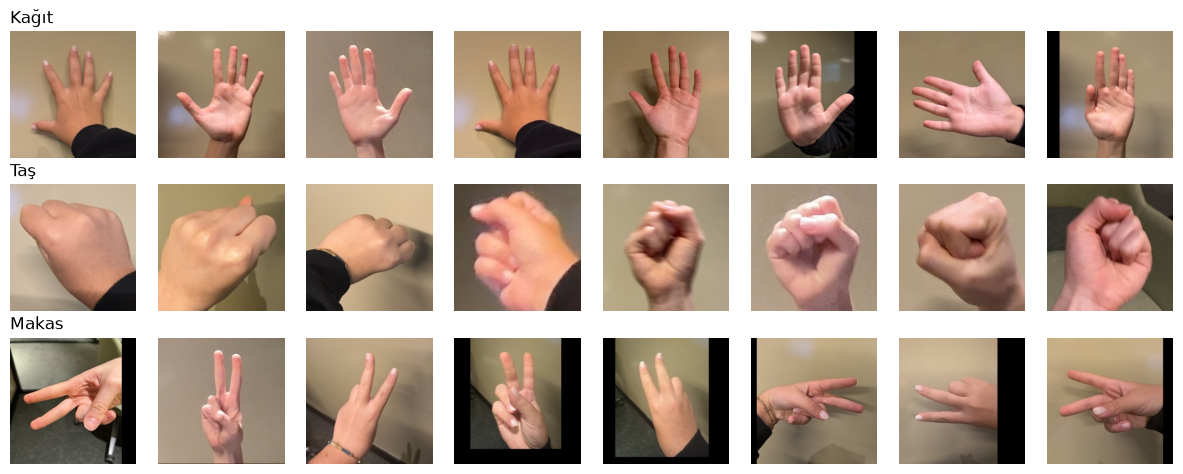

In [2]:
plain = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor()])
raw = {s: datasets.ImageFolder(DATA / s, transform=plain) for s in ("train", "val", "test")}
CLASSES = raw["train"].classes  # ImageFolder alfabetik sıralar: paper, rock, scissors
assert all(raw[s].classes == CLASSES for s in raw)

print(f"{'':10}" + "".join(f"{TR[c]:>8}" for c in CLASSES) + f"{'toplam':>8}")
for s, ds in raw.items():
    n = np.bincount(ds.targets, minlength=len(CLASSES))
    print(f"{s:10}" + "".join(f"{k:>8}" for k in n) + f"{n.sum():>8}")

fig, axes = plt.subplots(len(CLASSES), 8, figsize=(12, 4.8))
for r, c in enumerate(CLASSES):
    idx = [i for i, t in enumerate(raw["train"].targets) if t == r]
    for ax, i in zip(axes[r], random.sample(idx, 8)):
        ax.imshow(raw["train"][i][0].permute(1, 2, 0)); ax.axis("off")
    axes[r][0].set_title(TR[c], loc="left")
plt.tight_layout(); plt.show()

### 3. Data augmentation
Eğitim fotoğraflarını her epoch'ta biraz değiştirir: döndürme, hafif yakınlaştırma / kaydırma, ayna çevirme (sağ ve sol el), parlaklık / kontrast / renk değiştirme ve bazen hafif bulanıklık. Böylece model aynı fotoğrafı ezberleyemez ve farklı ışık ve açılara hazırlanır. Validation ve test fotoğrafları **değiştirilmez**.

**Çıktıda bak:** Aynı fotoğrafın 8 farklı hali. Hepsinde hareket hâlâ net anlaşılıyor olmalı.

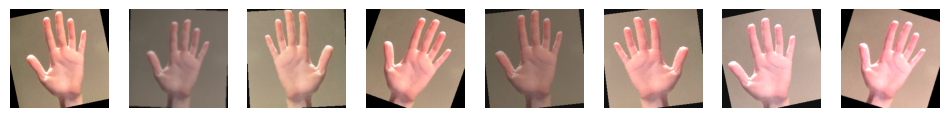

In [3]:
normalize = transforms.Normalize(MEAN, STD)
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.35, contrast=0.3, saturation=0.3, hue=0.03),
    transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.2),
    transforms.ToTensor(), normalize,
])
eval_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), normalize])

def to_rgb(t):  # normalizasyonu geri al: (3, H, W) → (H, W, 3) 0..1
    return (t.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1)

from PIL import Image
sample = Image.open(raw["train"].samples[0][0]).convert("RGB")
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for ax in axes:
    ax.imshow(to_rgb(train_tf(sample))); ax.axis("off")
plt.show()

### 4. DataLoader'lar
Fotoğrafları 32'şerli gruplar (batch) halinde modele verecek yükleyicileri hazırlar. Train datası her epoch'ta karıştırılır.

**Çıktıda bak:** Batch sayıları.

In [4]:
train_ds = datasets.ImageFolder(DATA / "train", transform=train_tf)
val_ds = datasets.ImageFolder(DATA / "val", transform=eval_tf)
test_ds = datasets.ImageFolder(DATA / "test", transform=eval_tf)

BATCH = 32
# num_workers=0: bu sunucuda paylaşımlı bellek (/dev/shm) çok küçük; data küçük olduğu için ana işlem yeterince hızlı
loader = lambda ds, shuffle: DataLoader(ds, batch_size=BATCH, shuffle=shuffle, num_workers=0,
                                        generator=torch.Generator().manual_seed(SEED))
train_dl, val_dl, test_dl = loader(train_ds, True), loader(val_ds, False), loader(test_ds, False)
print(f"train: {len(train_dl)} batch | val: {len(val_dl)} batch | test: {len(test_dl)} batch")

train: 11 batch | val: 3 batch | test: 3 batch


### 5. Eğitim ve ölçüm fonksiyonları
İki modelin de kullanacağı ortak fonksiyonlar:
- `train`: modeli eğitir. Her epoch sonunda train ve validation için **loss** ve **macro F1** hesaplar, canlı paneli günceller ve validation F1'i en yüksek olan ağırlıkları saklar.
- `evaluate`: bir datasetteki tahminleri ve loss'u hesaplar.
- `plot_history`: eğitim grafiği (F1 ve loss).
- `test_report`: test datasında macro F1, sınıf başına F1 ve karışıklık matrisi (confusion matrix).
- `gradcam`: modelin karar verirken fotoğrafın neresine baktığını gösteren ısı haritaları.
- `export_onnx`: modeli deneme sayfası ve web uygulaması için ONNX formatına çevirir.

**Çıktıda bak:** Bu hücre bir şey yazdırmaz, sadece fonksiyonları tanımlar.

In [5]:
import copy
import live

def proxy_link():
    """Uzak VS Code'da localhost linki senin bilgisayarında açılmaz; proxy linkini yazdırır."""
    port = live._SERVER.server_address[1] if live._SERVER else 8002
    proxy = os.environ.get("VSCODE_PROXY_URI")
    if proxy:
        print("Panel açılmadıysa bu linki aç:", proxy.replace("{{port}}", str(port)))

# parametre sayısı (only_train=True: sadece öğrenenler)
count = lambda m, only_train=False: sum(p.numel() for p in m.parameters() if p.requires_grad or not only_train)

@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    ys, ps, loss = [], [], 0.0
    for x, y in dl:
        out = model(x)
        loss += F.cross_entropy(out, y, reduction="sum").item()
        ys.append(y); ps.append(out.softmax(1))
    y, p = torch.cat(ys), torch.cat(ps)
    return y.numpy(), p.numpy(), loss / len(y)

def train(model, epochs, lr, history, name, view=None, weight_decay=0.05):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(train_dl))
    best = max([h["val_f1"] for h in history], default=-1)
    for epoch in range(epochs):
        t0 = time.time(); model.train()
        ys, ps, total = [], [], 0.0
        for i, (x, y) in enumerate(train_dl, start=1):
            out = model(x)
            loss = F.cross_entropy(out, y, label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            total += loss.item() * len(y); ys.append(y); ps.append(out.argmax(1))
            if view: view(model, history, i, len(train_dl), x=x, y=y)
        vy, vp, vloss = evaluate(model, val_dl)
        h = dict(epoch=len(history) + 1,
                 train_loss=total / len(train_ds), val_loss=vloss,
                 train_f1=f1_score(torch.cat(ys), torch.cat(ps), average="macro"),
                 val_f1=f1_score(vy, vp.argmax(1), average="macro"))
        history.append(h)
        if view: view(model, history, len(train_dl), len(train_dl), force=True)
        saved = ""
        if h["val_f1"] > best:
            best = h["val_f1"]; torch.save(model.state_dict(), MODELS / f"{name}_best.pt"); saved = " ← en iyi, kaydedildi"
        print(f"epoch {h['epoch']:>3} | train loss {h['train_loss']:.3f} F1 {h['train_f1']:.3f} | "
              f"val loss {h['val_loss']:.3f} F1 {h['val_f1']:.3f} | {time.time() - t0:.0f} sn{saved}")
    return history

def plot_history(history, title):
    e = [h["epoch"] for h in history]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
    a1.plot(e, [h["train_f1"] for h in history], label="train"); a1.plot(e, [h["val_f1"] for h in history], label="validation")
    a1.set_title(f"{title} — macro F1"); a1.set_xlabel("epoch"); a1.set_ylim(0, 1.02); a1.legend(); a1.grid(alpha=.3)
    a2.plot(e, [h["train_loss"] for h in history], label="train"); a2.plot(e, [h["val_loss"] for h in history], label="validation")
    a2.set_title(f"{title} — loss"); a2.set_xlabel("epoch"); a2.legend(); a2.grid(alpha=.3)
    plt.tight_layout(); plt.show()

def test_report(model, name, title):
    y, p, loss = evaluate(model, test_dl)
    pred = p.argmax(1)
    macro = f1_score(y, pred, average="macro")
    per = f1_score(y, pred, average=None)
    print(f"{title} — TEST macro F1: {macro:.3f}\n")
    print(classification_report(y, pred, target_names=[TR[c] for c in CLASSES], digits=3))
    cm = confusion_matrix(y, pred)
    fig, ax = plt.subplots(figsize=(3.6, 3.2))
    ax.imshow(cm, cmap="Blues")
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    names = [TR[c] for c in CLASSES]
    ax.set_xticks(range(len(names)), names); ax.set_yticks(range(len(names)), names)
    ax.set_xlabel("tahmin"); ax.set_ylabel("gerçek"); ax.set_title("Karışıklık matrisi"); plt.show()
    res = dict(model=title, test_macro_f1=float(macro), test_loss=float(loss),
               test_f1_per_class={c: float(f) for c, f in zip(CLASSES, per)},
               confusion_matrix=cm.tolist(), classes=CLASSES)
    (RESULTS / f"{name}.json").write_text(json.dumps(res, indent=2, ensure_ascii=False))
    return res

def gradcam(model, layer, n=8, title=""):
    """Grad-CAM: tahmin edilen sınıfın skorunun, seçilen katmandaki aktivasyonlara göre gradyanıyla ısı haritası."""
    model.eval()
    store = {}
    h1 = layer.register_forward_hook(lambda m, i, o: store.__setitem__("act", o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: store.__setitem__("grad", go[0]))
    rng = random.Random(SEED)
    idx = rng.sample(range(len(test_ds)), n)
    fig, axes = plt.subplots(2, n, figsize=(1.6 * n, 3.6))
    for k, i in enumerate(idx):
        x, y = test_ds[i]
        x = x[None].requires_grad_(True)
        out = model(x); pred = int(out.argmax(1))
        model.zero_grad(); out[0, pred].backward()
        w = store["grad"].mean((2, 3), keepdim=True)
        cam = F.relu((w * store["act"]).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0].detach()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        img = to_rgb(x[0].detach())
        axes[0][k].imshow(img); axes[0][k].axis("off")
        axes[0][k].set_title(f"{TR[CLASSES[y]]}", fontsize=9)
        axes[1][k].imshow(img); axes[1][k].imshow(cam, cmap="jet", alpha=0.45); axes[1][k].axis("off")
        p = out.softmax(1)[0, pred].item()
        axes[1][k].set_title(f"{TR[CLASSES[pred]]} %{p * 100:.0f}", fontsize=9, color="green" if pred == y else "red")
    h1.remove(); h2.remove()
    fig.suptitle(f"{title} — üst: gerçek, alt: tahmin + Grad-CAM (kırmızı = karara en çok etki eden yer)", fontsize=10)
    plt.tight_layout(); plt.show()

class WithSoftmax(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x).softmax(1)

def export_onnx(model, name, title, macro_f1):
    """İki dosya yazar: <name>_fp32.onnx (tam hassasiyet, sadece sunucuda) ve <name>.onnx
    (büyük Linear/MatMul ağırlıkları int8'e sıkıştırılmış; GitHub 100 MB sınırının altında, web için)."""
    import onnxruntime as ort
    from onnxruntime.quantization import QuantType, quantize_dynamic
    wrapped = WithSoftmax(model).eval()
    fp32, small = MODELS / f"{name}_fp32.onnx", MODELS / f"{name}.onnx"
    torch.onnx.export(wrapped, torch.randn(1, 3, IMG_SIZE, IMG_SIZE), fp32, input_names=["input"], output_names=["probs"],
                      dynamic_axes={"input": {0: "batch"}, "probs": {0: "batch"}}, opset_version=17, dynamo=False)
    wrapped.eval()  # export, modeli eski moduna (train) geri alır; Dropout/BatchNorm için tekrar eval
    quantize_dynamic(str(fp32), str(small), op_types_to_quantize=["MatMul", "Gemm"], weight_type=QuantType.QInt8)

    # Kontrol: ONNX dosyaları PyTorch ile aynı sonucu veriyor mu? (bütün test datası)
    x = torch.stack([test_ds[i][0] for i in range(len(test_ds))])
    y = np.array(test_ds.targets)
    with torch.no_grad():
        ref = wrapped(x).numpy()
    print(f"{'dosya':<22}{'boyut':>9}{'PyTorch ile fark':>18}{'test macro F1':>15}")
    print(f"{'PyTorch':<22}{'':>9}{'':>18}{f1_score(y, ref.argmax(1), average='macro'):>15.3f}")
    for path in (fp32, small):
        got = ort.InferenceSession(str(path), providers=["CPUExecutionProvider"]).run(None, {"input": x.numpy()})[0]
        print(f"{path.name:<22}{path.stat().st_size / 1e6:>7.1f}MB{np.abs(ref - got).max():>18.2e}"
              f"{f1_score(y, got.argmax(1), average='macro'):>15.3f}")
    meta = dict(model=title, file=small.name, classes=CLASSES, names_tr=[TR[c] for c in CLASSES],
                input_size=IMG_SIZE, mean=MEAN, std=STD, crop_pad=1.4, test_macro_f1=round(float(macro_f1), 4))
    (MODELS / f"{name}.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))

---
# Model B — ConvNeXt-Tiny (pretrained)

Milyonlarca görselle (ImageNet-22k) önceden eğitilmiş "hazır bir beyin". CPU'da hızlı olsun diye iki adımda eğitilir:
1. **Gövde donuk:** sadece son karar katmanı (head) öğrenir. 5 epoch, öğrenme hızı 1e-3.
2. **İnce ayar:** son aşama (stage 4) da çözülür ve birlikte öğrenir. 10 epoch, öğrenme hızı 1e-4.

### B1. Modeli oluştur
Hazır ağırlıkları indirir ve son katmanı 3 sınıfa (Taş, Kağıt, Makas) göre değiştirir.

**Çıktıda bak:** Toplam parametre sayısı (~27,8M) ve 1. adımda öğrenen parametre sayısı (çok az olmalı).

In [6]:
import timm

torch.manual_seed(SEED)
model_b = timm.create_model("convnext_tiny.fb_in22k_ft_in1k", pretrained=True, num_classes=len(CLASSES))

def set_trainable(model, parts):
    for p in model.parameters():
        p.requires_grad = False
    for part in parts:
        for p in part.parameters():
            p.requires_grad = True

set_trainable(model_b, [model_b.head])
print(f"Model B toplam: {count(model_b) / 1e6:.1f}M parametre | 1. adımda öğrenen: {count(model_b, True) / 1e3:.1f}K")

/home/coder/workspaces/rock-paper-scissors-computer-vision-2nd-week/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model B toplam: 27.8M parametre | 1. adımda öğrenen: 3.8K


### B2. Eğitim + canlı panel
Eğitimi başlatır. Tarayıcıda **"Model B öğreniyor"** paneli açılır: fotoğraf 4×4 karelere bölünür (Patchify), donuk aşamalar **gri**, öğrenen kısımlar **mavi** çizilir. 2. adım başlayınca son aşama da maviye döner.

**Çıktıda bak:** Her epoch'ta validation F1 yükselmeli. Train F1 çok yüksek ama validation F1 düşükse model ezberliyor (overfitting) demektir.

In [7]:
view_b = live.FineTuneLive(model_b, val_ds, to_rgb, CLASSES, epochs=15)
proxy_link()

t0 = time.time()
set_trainable(model_b, [model_b.head])                          # 1) gövde donuk
hist_b = train(model_b, 5, 1e-3, [], "model_b", view=view_b)
set_trainable(model_b, [model_b.stages[-1], model_b.head])      # 2) son aşama çözülür
print(f"--- ince ayar: son aşama da öğreniyor ({count(model_b, True) / 1e6:.1f}M parametre) ---")
hist_b = train(model_b, 10, 1e-4, hist_b, "model_b", view=view_b)
view_b.close()

model_b.load_state_dict(torch.load(MODELS / "model_b_best.pt"))  # validation F1'i en iyi epoch
(RESULTS / "model_b_history.json").write_text(json.dumps(hist_b, indent=2))
print(f"Bitti: {(time.time() - t0) / 60:.1f} dk | en iyi validation F1: {max(h['val_f1'] for h in hist_b):.3f}")

Canlı panel: http://localhost:8002/  (tarayıcıda açılmadıysa bu linke tıkla)
Panel açılmadıysa bu linki aç: https://student.exposureai.org/lab/proxy/8002/


epoch   1 | train loss 0.814 F1 0.673 | val loss 0.462 F1 0.870 | 4 sn ← en iyi, kaydedildi


epoch   2 | train loss 0.483 F1 0.919 | val loss 0.324 F1 0.874 | 5 sn ← en iyi, kaydedildi


epoch   3 | train loss 0.444 F1 0.944 | val loss 0.283 F1 0.942 | 5 sn ← en iyi, kaydedildi


epoch   4 | train loss 0.418 F1 0.959 | val loss 0.273 F1 0.930 | 4 sn


...

epoch  11 | train loss 0.304 F1 1.000 | val loss 0.144 F1 0.987 | 6 sn


epoch  12 | train loss 0.303 F1 1.000 | val loss 0.132 F1 0.987 | 6 sn


epoch  13 | train loss 0.302 F1 1.000 | val loss 0.133 F1 0.987 | 6 sn


epoch  14 | train loss 0.301 F1 1.000 | val loss 0.131 F1 0.987 | 6 sn


epoch  15 | train loss 0.302 F1 1.000 | val loss 0.131 F1 0.987 | 6 sn
Bitti: 1.3 dk | en iyi validation F1: 0.987


### B3. Eğitim grafiği
Train ve validation için macro F1 ve loss eğrileri.

**Çıktıda bak:** İki eğri birbirine yakın mı? Validation loss yükselmeye başladıysa model ezberlemeye başlamış demektir.

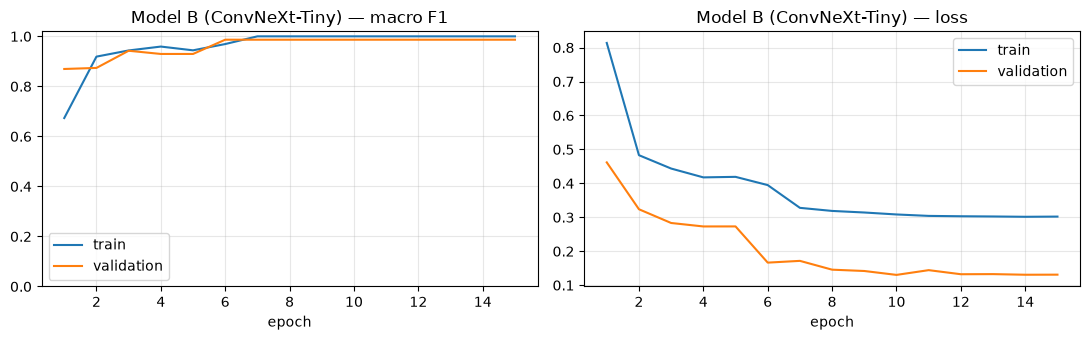

In [8]:
plot_history(hist_b, "Model B (ConvNeXt-Tiny)")

### B4. Test sonuçları
Model **hiç görmediği** test fotoğraflarında ölçülür. Ana metrik **macro F1**: üç hareketi eşit ağırlıkla değerlendirir.

**Çıktıda bak:** Macro F1, sınıf başına F1 (hangi harekette zorlanıyor?) ve karışıklık matrisinde hangi hareketlerin birbirine karıştığı.

Model B (ConvNeXt-Tiny) — TEST macro F1: 1.000

              precision    recall  f1-score   support

       Kağıt      1.000     1.000     1.000        23
         Taş      1.000     1.000     1.000        27
       Makas      1.000     1.000     1.000        23

    accuracy                          1.000        73
   macro avg      1.000     1.000     1.000        73
weighted avg      1.000     1.000     1.000        73



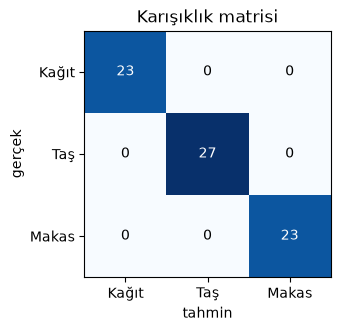

In [9]:
res_b = test_report(model_b, "model_b", "Model B (ConvNeXt-Tiny)")

### B5. Grad-CAM: model nereye bakıyor?
Birkaç test fotoğrafının üstüne, modelin karar verirken en çok baktığı yerleri ısı haritası olarak çizer. Kırmızı bölgeler kararda en etkili yerlerdir. Sadece inceleme amaçlı.

**Çıktıda bak:** İyi bir model parmaklara ve elin şekline bakar. Arka plana veya kola bakıyorsa yanlış şeyi öğrenmiş olabilir.

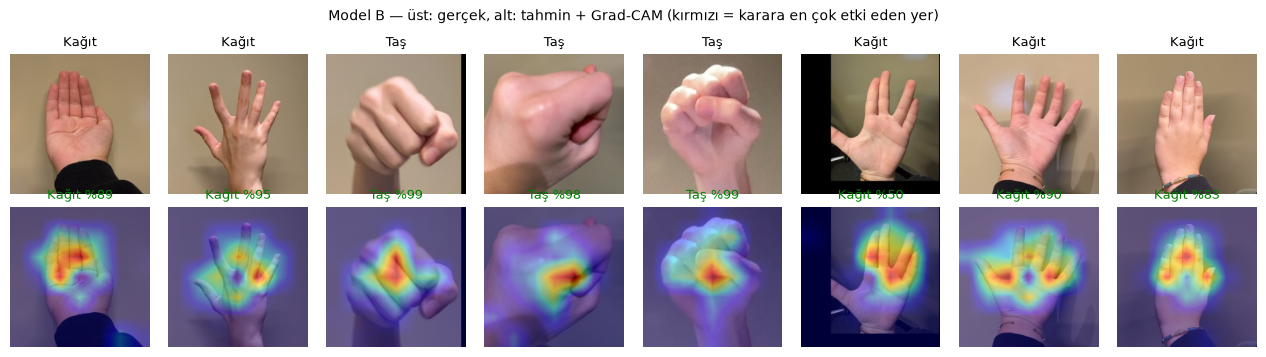

In [10]:
gradcam(model_b, model_b.stages[-1], title="Model B")

### B6. ONNX'e aktar
Modeli iki ONNX dosyası olarak kaydeder:
- `models/model_b_fp32.onnx`: tam hassasiyet (~110 MB). GitHub'ın 100 MB sınırını aştığı için repoya girmez.
- `models/model_b.onnx`: büyük ağırlıkları int8'e sıkıştırılmış sürüm (~4 kat küçük). Repoya, deneme sayfasına ve web uygulamasına bu gider.

Yanına sınıf sırasını ve ön işleme ayarlarını içeren `models/model_b.json` dosyası da yazılır.

**Çıktıda bak:** fp32 dosyasının PyTorch ile farkı çok küçük olmalı (1e-5 civarı). Sıkıştırılmış dosyanın test macro F1'i PyTorch ile aynı ya da çok yakın olmalı.

In [11]:
export_onnx(model_b, "model_b", "ConvNeXt-Tiny (pretrained)", res_b["test_macro_f1"])

/tmp/ipykernel_492461/3890365643.py:122: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(wrapped, torch.randn(1, 3, IMG_SIZE, IMG_SIZE), fp32, input_names=["input"], output_names=["probs"],


dosya                     boyut  PyTorch ile fark  test macro F1
PyTorch                                                    1.000


model_b_fp32.onnx       111.4MB          2.95e-06          1.000


model_b.onnx             33.8MB          1.64e-01          0.986


---
# Model A — Kendi CNN'im (sıfırdan)

Ağırlıkları rastgele başlayan, sadece benim datamla öğrenen bir CNN. Onaylanan mimari (DENEY_GUNLUGU.md):

```
5 blok:  Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2   (kanallar 32 → 64 → 128 → 128 → 256, 224 px → 7×7)
Karar:   Flatten (12544) → Dropout 0.5 → Linear 2000 → ReLU → Dropout 0.5 → Linear 3
```

### A1. Modeli oluştur
**Çıktıda bak:** Toplam parametre sayısı (~25,8M). Bunların çoğu büyük Linear katmanında.

In [6]:
def block(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))

torch.manual_seed(SEED)
model_a = nn.Sequential(
    block(3, 32), block(32, 64), block(64, 128), block(128, 128), block(128, 256),
    nn.Flatten(), nn.Dropout(0.5), nn.Linear(256 * 7 * 7, 2000), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(2000, len(CLASSES)),
)
print(f"Model A toplam: {count(model_a) / 1e6:.1f}M parametre "
      f"(konvolüsyon blokları: {sum(count(m) for m in model_a[:5]) / 1e6:.2f}M)")

Model A toplam: 25.6M parametre (konvolüsyon blokları: 0.54M)


### A2. Eğitim + canlı panel
60 epoch eğitir. Tarayıcıda **"Model A öğreniyor"** paneli açılır: tek bir damga (gerçek 3×3 ağırlıklar) fotoğrafın üstünden geçer, Conv / BatchNorm / ReLU / MaxPool adımlarının kule şehrine ne yaptığı görünür.

**Çıktıda bak:** Sıfırdan başladığı için ilk epoch'larda F1 düşük (~0.33 = rastgele tahmin) olur, sonra yükselir. Train F1 ile validation F1 arasındaki fark büyürse ezber var demektir.

In [7]:
view_a = live.CNNLive(model_a, val_ds, to_rgb, CLASSES, epochs=60)
proxy_link()

t0 = time.time()
hist_a = train(model_a, 60, 1e-3, [], "model_a", view=view_a, weight_decay=1e-4)
view_a.close()

model_a.load_state_dict(torch.load(MODELS / "model_a_best.pt"))
(RESULTS / "model_a_history.json").write_text(json.dumps(hist_a, indent=2))
print(f"Bitti: {(time.time() - t0) / 60:.1f} dk | en iyi validation F1: {max(h['val_f1'] for h in hist_a):.3f}")

Canlı panel: http://localhost:8002/  (tarayıcıda açılmadıysa bu linke tıkla)


Panel açılmadıysa bu linki aç: https://student.exposureai.org/lab/proxy/8002/


epoch   1 | train loss 8.941 F1 0.342 | val loss 1.460 F1 0.282 | 4 sn ← en iyi, kaydedildi


epoch   2 | train loss 2.589 F1 0.351 | val loss 1.495 F1 0.391 | 4 sn ← en iyi, kaydedildi


epoch   3 | train loss 1.531 F1 0.405 | val loss 1.146 F1 0.459 | 4 sn ← en iyi, kaydedildi


...

epoch  56 | train loss 0.387 F1 0.967 | val loss 0.129 F1 0.971 | 4 sn


epoch  57 | train loss 0.369 F1 0.973 | val loss 0.129 F1 0.971 | 4 sn


epoch  58 | train loss 0.371 F1 0.985 | val loss 0.128 F1 0.956 | 4 sn


epoch  59 | train loss 0.374 F1 0.979 | val loss 0.129 F1 0.971 | 4 sn


epoch  60 | train loss 0.379 F1 0.976 | val loss 0.131 F1 0.971 | 4 sn
Bitti: 3.9 dk | en iyi validation F1: 0.986


### A3. Eğitim grafiği
**Çıktıda bak:** Train ve validation eğrileri arasındaki fark (ezber var mı?).

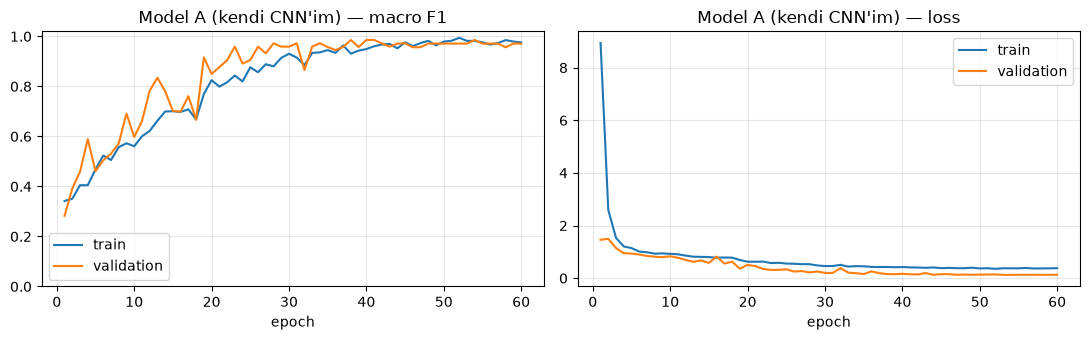

In [8]:
plot_history(hist_a, "Model A (kendi CNN'im)")

### A4. Test sonuçları
**Çıktıda bak:** Macro F1 ve sınıf başına F1. Model B ile aynı test fotoğrafları kullanılıyor.

Model A (kendi CNN'im) — TEST macro F1: 0.987

              precision    recall  f1-score   support

       Kağıt      1.000     1.000     1.000        23
         Taş      1.000     0.963     0.981        27
       Makas      0.958     1.000     0.979        23

    accuracy                          0.986        73
   macro avg      0.986     0.988     0.987        73
weighted avg      0.987     0.986     0.986        73



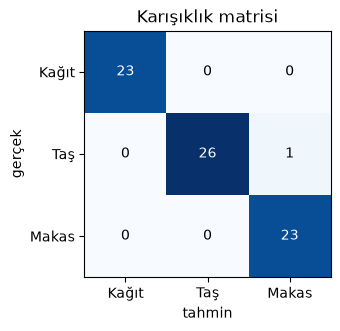

In [9]:
res_a = test_report(model_a, "model_a", "Model A (kendi CNN'im)")

### A5. Grad-CAM: model nereye bakıyor?
Son konvolüsyon katmanına göre ısı haritası.

**Çıktıda bak:** Parmaklara mı bakıyor, arka plana mı?

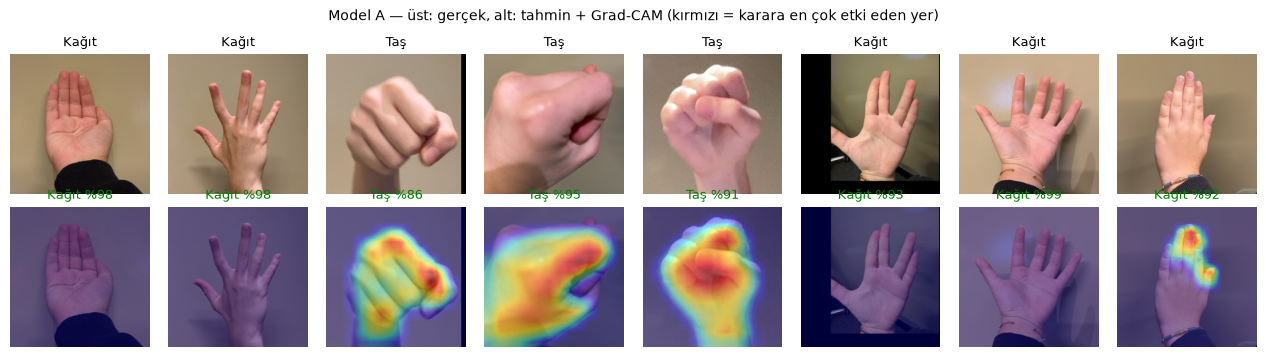

In [10]:
gradcam(model_a, model_a[4][0], title="Model A")

### A6. ONNX'e aktar
**Çıktıda bak:** `models/model_a.onnx` oluştu ve test macro F1'i PyTorch ile aynı ya da çok yakın.

In [11]:
export_onnx(model_a, "model_a", "Kendi CNN'im (sıfırdan)", res_a["test_macro_f1"])

/tmp/ipykernel_1598/3490320695.py:125: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(wrapped, torch.randn(1, 3, IMG_SIZE, IMG_SIZE), fp32, input_names=["input"], output_names=["probs"],


dosya                     boyut  PyTorch ile fark  test macro F1
PyTorch                                                    0.987


model_a_fp32.onnx       102.5MB          3.28e-07          0.987
model_a.onnx             27.3MB          2.13e-03          0.987


---
# Karşılaştırma (iki model de eğitildikten sonra)

### K1. Metrik tablosu
İki modelin test sonuçlarını `results/` klasöründen okuyup yan yana koyar. Kernel yeniden başlatılmış olsa bile çalışır.

**Çıktıda bak:** Macro F1 farkı = pretraining'in yarattığı fark (iki model aynı boyutta ve aynı datayla eğitildi).

In [12]:
rows = [json.loads((RESULTS / f"{n}.json").read_text()) for n in ("model_a", "model_b")
        if (RESULTS / f"{n}.json").exists()]
if len(rows) < 2:
    print("İki modelin de test sonuçları gerekiyor. Eksik model:", {"model_a", "model_b"} - {
        n for n in ("model_a", "model_b") if (RESULTS / f"{n}.json").exists()})
else:
    names = [TR[c] for c in rows[0]["classes"]]
    print(f"{'Model':<28}{'macro F1':>9}" + "".join(f"{'F1 ' + n:>11}" for n in names) + f"{'test loss':>11}")
    for r in rows:
        print(f"{r['model']:<28}{r['test_macro_f1']:>9.3f}"
              + "".join(f"{r['test_f1_per_class'][c]:>11.3f}" for c in r["classes"]) + f"{r['test_loss']:>11.3f}")
    diff = rows[1]["test_macro_f1"] - rows[0]["test_macro_f1"]
    print(f"\nPretraining farkı (B − A): {diff:+.3f} macro F1")

Model                        macro F1   F1 Kağıt     F1 Taş   F1 Makas  test loss
Model A (kendi CNN'im)          0.987      1.000      0.981      0.979      0.126
Model B (ConvNeXt-Tiny)         1.000      1.000      1.000      1.000      0.119

Pretraining farkı (B − A): +0.013 macro F1


### K2. Eğitim eğrileri yan yana
**Çıktıda bak:** Hangi model daha hızlı öğrendi, hangisi daha çok ezberledi?

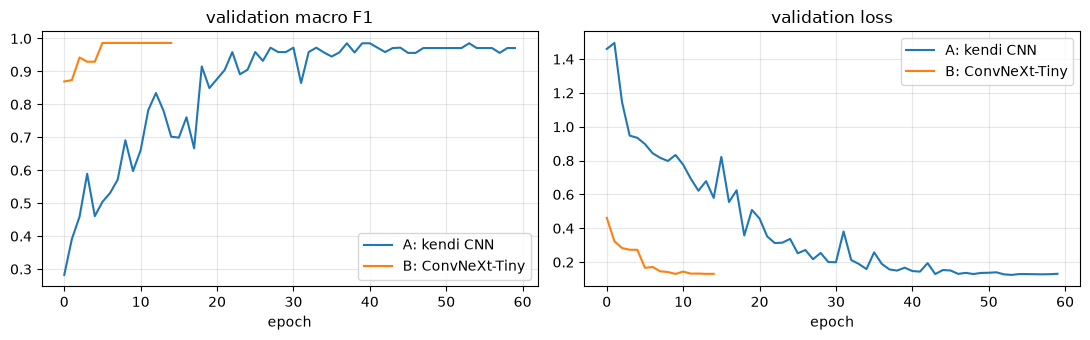

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for n, title in (("model_a", "A: kendi CNN"), ("model_b", "B: ConvNeXt-Tiny")):
    p = RESULTS / f"{n}_history.json"
    if p.exists():
        h = json.loads(p.read_text())
        ax[0].plot([x["val_f1"] for x in h], label=title); ax[1].plot([x["val_loss"] for x in h], label=title)
ax[0].set_title("validation macro F1"); ax[1].set_title("validation loss")
for a in ax:
    a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
# V2 — Yeni fotoğraflarla yeniden eğitim (kameraya dayanıklı tarif)

Yukarıdaki A ve B bölümleri ilk datasetle (482 el) eğitildi. Kamerada denerken model özellikle **makası** karıştırdı. Bu yüzden:
- **Yeni fotoğraflar** eklendi: kağıt ve makas arttı, toplam **657 el** (eski train / val / test dosyaları yerinde kaldı, yeniler dağıtıldı).
- **Yeni tarif** (`improve.py`): kırpma her seferinde elin etrafındaki geniş "bağlam" karesinden (`tools/crop_context.py`) farklı pay ve kaymayla kesilir; üstüne kamera bozulmaları (hareket bulanıklığı, JPEG, gürültü, düşük çözünürlük, karanlık) eklenir. Kamerada MediaPipe'ın kutusu her karede biraz oynadığı için model buna alışır.
- **Zor test**: aynı val / test fotoğraflarının 12 farklı bozulmuş hali (kutu kayması, karanlık, siyah-beyaz…). Model seçimi sadece val ile yapılır, test sadece raporlanır.

**Adil karşılaştırma:** iki model yine aynı data, aynı tarif ve aynı bölünmeyle eğitilir. Bu bölüm sadece ortak hazırlık hücrelerini (1–5) ister; A ve B bölümlerini yeniden çalıştırmaya gerek yok.

### V1. Yeni datasetin sayıları
**Çıktıda bak:** Her sınıfın train / val / test sayıları; test datası eğitimde hiç kullanılmaz.

In [6]:
import improve

print(f"{'':10}" + "".join(f"{TR[c]:>8}" for c in CLASSES) + f"{'toplam':>8}")
for s in ("train", "val", "test"):
    n = np.bincount(datasets.ImageFolder(DATA / s).targets, minlength=len(CLASSES))
    print(f"{s:10}" + "".join(f"{k:>8}" for k in n) + f"{n.sum():>8}")

             Kağıt     Taş   Makas  toplam
train          173     124     160     457
val             38      27      35     100
test            38      27      35     100


### V2. Model B (ConvNeXt-Tiny) — yeni tarifle fine-tuning
`improve.py`'deki `B_deep` tarifi: önce sadece karar katmanı, sonra son iki aşama açılır. En iyi epoch, **temiz + zor validation** loss'una göre seçilir.

**Çıktıda bak:** train loss ve val loss birlikte düşüyor mu? Val loss artmaya başlarsa ezber var demektir.

In [7]:
improve.run("B_deep", seed=1, threads=48)

/home/coder/workspaces/rock-paper-scissors-computer-vision-2nd-week/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


B_deep s1 epoch   1 | train loss 0.775 | val (temiz+zor) loss 0.580


B_deep s1 epoch   2 | train loss 0.547 | val (temiz+zor) loss 0.478


B_deep s1 epoch   3 | train loss 0.524 | val (temiz+zor) loss 0.461


B_deep s1 epoch   4 | train loss 0.493 | val (temiz+zor) loss 0.342


...

B_deep s1 epoch  15 | train loss 0.302 | val (temiz+zor) loss 0.180


B_deep s1 epoch  16 | train loss 0.303 | val (temiz+zor) loss 0.182


B_deep s1 epoch  17 | train loss 0.302 | val (temiz+zor) loss 0.182


B_deep s1 epoch  18 | train loss 0.300 | val (temiz+zor) loss 0.182


BITTI B_deep s1: test temiz F1 1.000 | test zor F1 0.988 | val zor F1 0.955 | 7.7 dk


### V3. Model B — sonuçlar
Eğitim eğrisi, test datasında **macro F1 + sınıf başına F1 + karışıklık matrisi**, zor test ve Grad-CAM. Sonra ONNX'e aktarılır (`models/model_b.onnx`, deneme sayfası bunu kullanır).

**Çıktıda bak:** Makas F1'i ve karışıklık matrisinde makasın neyle karıştığı; Grad-CAM'de modelin parmaklara bakması.

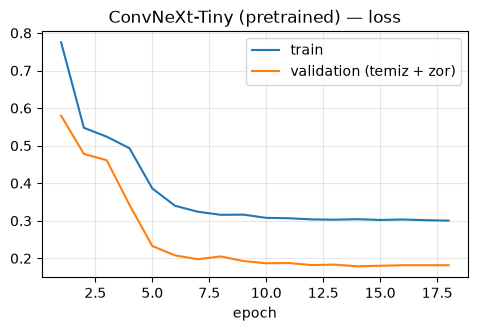

ConvNeXt-Tiny (pretrained) — TEST macro F1: 1.000

              precision    recall  f1-score   support

       Kağıt      1.000     1.000     1.000        38
         Taş      1.000     1.000     1.000        27
       Makas      1.000     1.000     1.000        35

    accuracy                          1.000       100
   macro avg      1.000     1.000     1.000       100
weighted avg      1.000     1.000     1.000       100



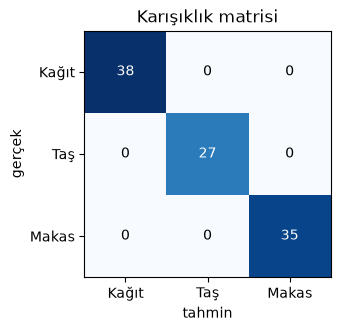

Zor test (test fotoğraflarının bozulmuş halleri) macro F1:
  kutu küçük (pay 1.1)        1.000
  kutu büyük (pay 1.9)        0.989
  kayma sağ-aşağı             1.000
  kayma sol-yukarı            0.991
  eğik el (35°)               0.991
  karanlık                    1.000
  parlak                      0.982
  gürültü                     0.989
  hareket bulanıklığı         0.980
  JPEG kalite 15              0.989
  düşük çözünürlük (48 px)    0.971
  siyah-beyaz                 0.973
  zor ortalama                0.988


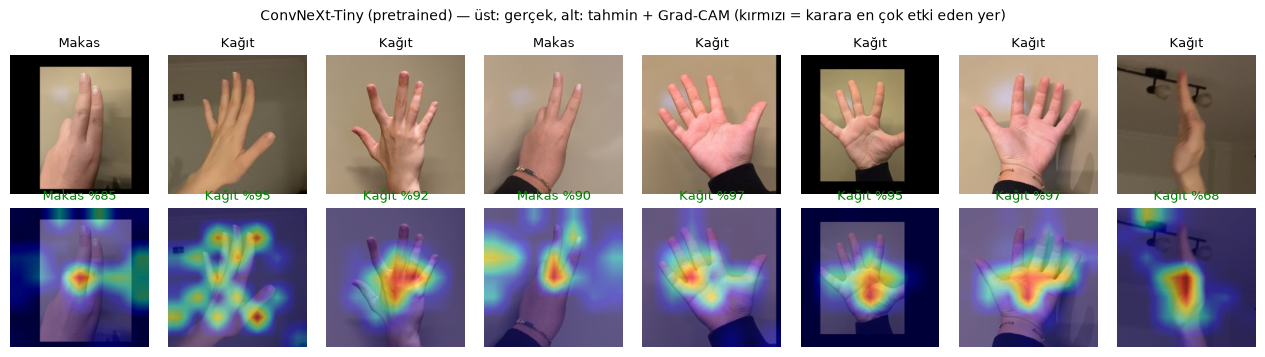

dosya                       boyut  PyTorch ile fark  test macro F1


model_b_fp32.onnx         111.4MB          1.85e-06          1.000


model_b.onnx               33.8MB          1.77e-01          1.000


In [8]:
def v2_results(cfg, name, title, layer_of):
    r = json.loads((improve.OUT / f"{cfg}_s1.json").read_text())
    e = [h["epoch"] for h in r["history"]]
    plt.figure(figsize=(5.5, 3.2))
    plt.plot(e, [h["train_loss"] for h in r["history"]], label="train")
    plt.plot(e, [h["val_loss"] for h in r["history"]], label="validation (temiz + zor)")
    plt.title(f"{title} — loss"); plt.xlabel("epoch"); plt.legend(); plt.grid(alpha=.3); plt.show()
    model = improve.CONFIGS[cfg]["model"]()
    model.load_state_dict(torch.load(improve.CKPT / f"{cfg}_s1.pt")); model.eval()
    res = test_report(model, f"{name}_v2", title)
    print("Zor test (test fotoğraflarının bozulmuş halleri) macro F1:")
    for k, v in r["test"].items():
        if k != "temiz":
            print(f"  {k:<28}{v['f1']:.3f}")
    gradcam(model, layer_of(model), title=title)
    improve.export(cfg, 1, name, title)
    return res

res_b2 = v2_results("B_deep", "model_b", "ConvNeXt-Tiny (pretrained)", lambda m: m.stages[-1])

### V4. Model A (kendi CNN'im, sıfırdan) — yeni tarifle eğitim
Onaylanan aynı mimari (25,6M parametre), `A_new2_long` tarifi: 200 epoch. Sıfırdan öğrendiği için B'den çok daha uzun sürer (~30 dk).

**Çıktıda bak:** İlk epoch'larda loss yavaş düşer (hazır beyin yok); B ile farkı burada görürsün.

In [9]:
improve.run("A_new2_long", seed=1, threads=48)

A_new2_long s1 epoch   1 | train loss 7.029 | val (temiz+zor) loss 2.084


A_new2_long s1 epoch   2 | train loss 1.664 | val (temiz+zor) loss 1.318


A_new2_long s1 epoch   3 | train loss 1.342 | val (temiz+zor) loss 1.076


A_new2_long s1 epoch   4 | train loss 1.092 | val (temiz+zor) loss 1.025


A_new2_long s1 epoch   5 | train loss 1.108 | val (temiz+zor) loss 1.033


...

A_new2_long s1 epoch 197 | train loss 0.459 | val (temiz+zor) loss 0.269


A_new2_long s1 epoch 198 | train loss 0.469 | val (temiz+zor) loss 0.266


A_new2_long s1 epoch 199 | train loss 0.473 | val (temiz+zor) loss 0.269


A_new2_long s1 epoch 200 | train loss 0.477 | val (temiz+zor) loss 0.267


BITTI A_new2_long s1: test temiz F1 0.982 | test zor F1 0.931 | val zor F1 0.924 | 32.5 dk


### V5. Model A — sonuçlar
**Çıktıda bak:** Makas F1'i ve zor testte hangi bozulmada düştüğü (siyah-beyaz, parlaklık…).

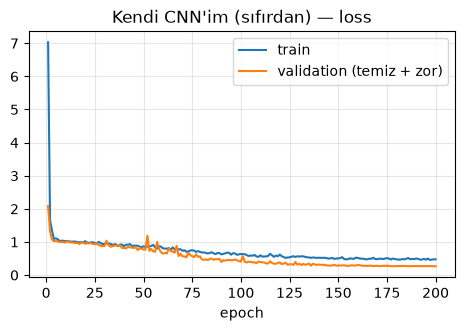

Kendi CNN'im (sıfırdan) — TEST macro F1: 0.982

              precision    recall  f1-score   support

       Kağıt      1.000     0.947     0.973        38
         Taş      1.000     1.000     1.000        27
       Makas      0.946     1.000     0.972        35

    accuracy                          0.980       100
   macro avg      0.982     0.982     0.982       100
weighted avg      0.981     0.980     0.980       100



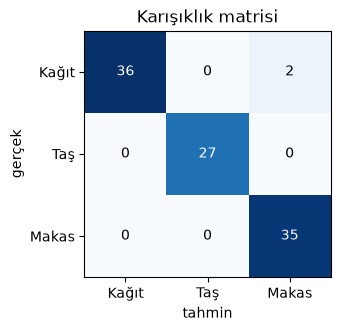

Zor test (test fotoğraflarının bozulmuş halleri) macro F1:
  kutu küçük (pay 1.1)        0.932
  kutu büyük (pay 1.9)        0.951
  kayma sağ-aşağı             0.913
  kayma sol-yukarı            0.804
  eğik el (35°)               0.905
  karanlık                    0.936
  parlak                      0.935
  gürültü                     0.963
  hareket bulanıklığı         0.971
  JPEG kalite 15              0.954
  düşük çözünürlük (48 px)    0.960
  siyah-beyaz                 0.942
  zor ortalama                0.931


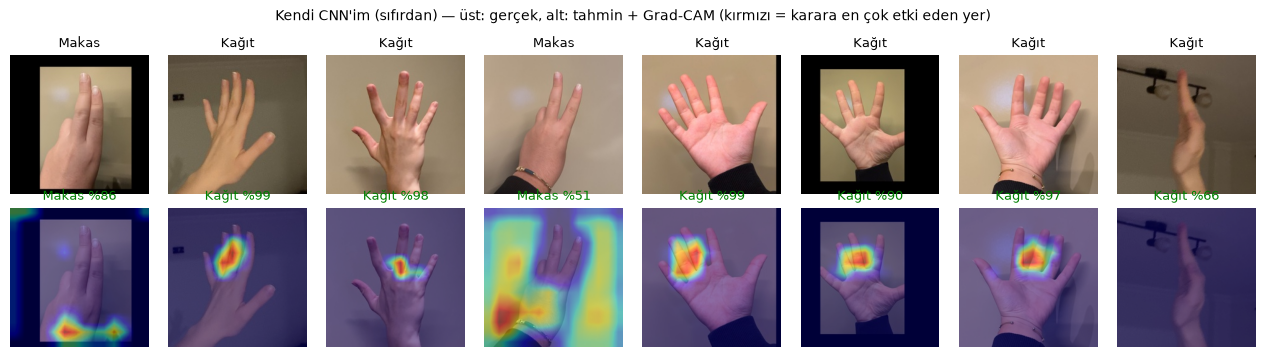

dosya                       boyut  PyTorch ile fark  test macro F1


model_a_fp32.onnx         102.5MB          5.96e-07          0.982


model_a.onnx               27.3MB          5.35e-03          0.982


In [10]:
res_a2 = v2_results("A_new2_long", "model_a", "Kendi CNN'im (sıfırdan)", lambda m: m[4][0])

### V6. Karşılaştırma tablosu (yeni data)
**Çıktıda bak:** Temiz testte fark küçük olabilir; asıl fark **zor test**te (kameraya benzer koşullar) görünür.

In [11]:
rows = []
for cfg, n, title in (("A_new2_long", "model_a_v2", "A: kendi CNN"), ("B_deep", "model_b_v2", "B: ConvNeXt-Tiny")):
    t = json.loads((RESULTS / f"{n}.json").read_text())
    z = json.loads((improve.OUT / f"{cfg}_s1.json").read_text())
    rows.append((title, t, z))
names = [TR[c] for c in CLASSES]
print(f"{'Model':<20}{'macro F1':>9}" + "".join(f"{'F1 ' + n:>11}" for n in names) + f"{'zor test F1':>13}")
for title, t, z in rows:
    print(f"{title:<20}{t['test_macro_f1']:>9.3f}" + "".join(f"{t['test_f1_per_class'][c]:>11.3f}" for c in CLASSES)
          + f"{z['test']['zor ortalama']['f1']:>13.3f}")
print(f"\nPretraining farkı (B − A): temiz {rows[1][1]['test_macro_f1'] - rows[0][1]['test_macro_f1']:+.3f} | "
      f"zor {rows[1][2]['test']['zor ortalama']['f1'] - rows[0][2]['test']['zor ortalama']['f1']:+.3f} macro F1")

Model                macro F1   F1 Kağıt     F1 Taş   F1 Makas  zor test F1
A: kendi CNN            0.982      0.973      1.000      0.972        0.931
B: ConvNeXt-Tiny        1.000      1.000      1.000      1.000        0.988

Pretraining farkı (B − A): temiz +0.018 | zor +0.057 macro F1
